# 06. Cross-Encoder Signal Evaluation
**AI-Based Resume–Job Matching & Skill Gap Analysis — Phase 7**

### 1. Objective
Throughout Phases 1 to 6C, our candidate matching models relied on **bi-encoders** (`all-MiniLM-L6-v2` and `all-mpnet-base-v2`) and tabular lexical/skill features. Bi-encoders independently map resumes and job descriptions into fixed-size dense vectors ($d=384$ or $d=768$) before computing cosine similarity.

While computationally fast ($O(N + M)$ encoding), bi-encoders suffer from an intrinsic information bottleneck: compressing a 500-word resume and a 400-word job description into a single point eliminates token-level cross-attention.

**Objective of Phase 7**:
Evaluate whether a **Cross-Encoder** (`cross-encoder/ms-marco-MiniLM-L-6-v2`), which performs full multi-head cross-attention across concatenated resume–job pairs ($O(N \times M)$), produces complementary interaction signals that improve multi-class match classification over the reference model (**Model A**).


### 2. Current Reference Model (Model A)
- **Architecture**: Supervised Logistic Regression ($C=0.1$, `class_weight='balanced'`, `StandardScaler`)
- **Features (22)**:
  - Lexical Similarity: `tfidf_cosine_similarity`
  - Bi-Encoder Semantic Similarity: `sbert_cosine_similarity` (`all-MiniLM-L6-v2`)
  - Skill Features: `skill_coverage`, detected skill counts, matched/missing counts
  - Length & Ratio Features: document word/char counts, ratios, log transforms
  - Token Overlap: `jaccard_similarity`, shared unique tokens
- **Locked Benchmark Performance**:
  - `candidate_validation` Macro F1: **0.4603**
  - `candidate_test` (Unseen Candidates) Macro F1: **0.4735** | Accuracy: **0.5154**
  - `official_test` (Unseen JDs) Macro F1: **0.4220** | Accuracy: **0.4508**


### 3. Cross-Encoder Model Architecture
- **Pretrained Checkpoint**: `cross-encoder/ms-marco-MiniLM-L-6-v2`
- **Mechanism**: The resume text and job description text are concatenated as a single sequence `[CLS] Resume [SEP] Job Description [SEP]` and passed through 6 Transformer layers.
- **Cross-Attention**: Every word in the resume directly attends to every word in the job description at all attention heads, outputting a continuous scalar relevance score.
- **No Fine-Tuning**: Evaluated zero-shot / off-the-shelf to measure the raw transfer value of token-level relevance modeling.


### 4. CPU Feasibility Benchmark
Before processing the full corpus of 8,000 resume–job pairs, we conducted a controlled latency and throughput benchmark on a 100-pair sample.


In [1]:
import pandas as pd
from IPython.display import display

latency_df = pd.read_csv('../data/evaluation/phase7_cross_encoder_latency.csv')
print("=== CPU Feasibility Benchmark Results ===")
display(latency_df)


=== CPU Feasibility Benchmark Results ===


,model_name,loading_time_s,benchmark_pairs,benchmark_time_s,avg_latency_per_pair_ms,throughput_pairs_per_sec,memory_mb,est_total_pairs,est_total_time_min
0,cross-encoder/ms-marco-MiniLM-L-6-v2,8.59,100,13.7,136.98,7.3,207.8,8000,18.26


### 5. Cross-Encoder Score Generation
Cross-Encoder relevance scores were computed across all 8,000 pairs:
- `candidate_train`: 3,758 pairs
- `candidate_validation`: 1,282 pairs
- `candidate_test`: 1,201 pairs
- `official_test`: 1,759 pairs

All scores are precomputed and cached in deterministic numpy arrays under `data/evaluation/`.


In [2]:
import numpy as np

train_ce = np.load('../data/evaluation/phase7_ce_scores_train.npy')
val_ce   = np.load('../data/evaluation/phase7_ce_scores_validation.npy')
test_ce  = np.load('../data/evaluation/phase7_ce_scores_test.npy')
off_ce   = np.load('../data/evaluation/phase7_ce_scores_official_test.npy')

print(f"Loaded Cross-Encoder scores:")
print(f"  Train:      {len(train_ce)} scores (mean: {train_ce.mean():.4f}, std: {train_ce.std():.4f})")
print(f"  Validation: {len(val_ce)} scores (mean: {val_ce.mean():.4f}, std: {val_ce.std():.4f})")
print(f"  Test:       {len(test_ce)} scores (mean: {test_ce.mean():.4f}, std: {test_ce.std():.4f})")
print(f"  Official:   {len(off_ce)} scores (mean: {off_ce.mean():.4f}, std: {off_ce.std():.4f})")


Loaded Cross-Encoder scores:
  Train:      3758 scores (mean: -6.7926, std: 2.2245)
  Validation: 1282 scores (mean: -6.9031, std: 2.2952)
  Test:       1201 scores (mean: -6.7395, std: 2.1224)
  Official:   1759 scores (mean: -6.7950, std: 2.1711)


### 6, 7, 8. Controlled Model Formulations
We evaluate three strictly controlled models:
- **Model A (Reference)**: The locked 22-feature supervised Logistic Regression model (`C=0.1`, `class_weight='balanced'`).
- **Model B (Cross-Encoder Diagnostic)**: Logistic Regression trained exclusively on the single 1D `cross_encoder_score` feature to measure its standalone predictive power.
- **Model C (Cross-Encoder Augmented)**: 23-feature model combining all 22 reference features with `cross_encoder_score` (`StandardScaler`, `LogisticRegression(C=0.1, class_weight='balanced')`).


### 9, 10, 11. Experimental Results Across Splits
Performance metrics across Validation (model selection), Candidate Test (unseen candidates), and Official Test (unseen job descriptions).


=== Overall Performance Summary ===


,model,val_macro_f1,cand_test_macro_f1,cand_test_accuracy,off_test_macro_f1,off_test_accuracy
0,Model A (Reference 22-feat),0.4603,0.4735,0.5154,0.4220,0.4508
1,Model B (Cross-Encoder Only),0.3561,0.3800,0.4738,0.3366,0.4144
2,Model C (Cross-Encoder Augmented 23-feat),0.4590,0.4772,0.5187,0.4211,0.4503


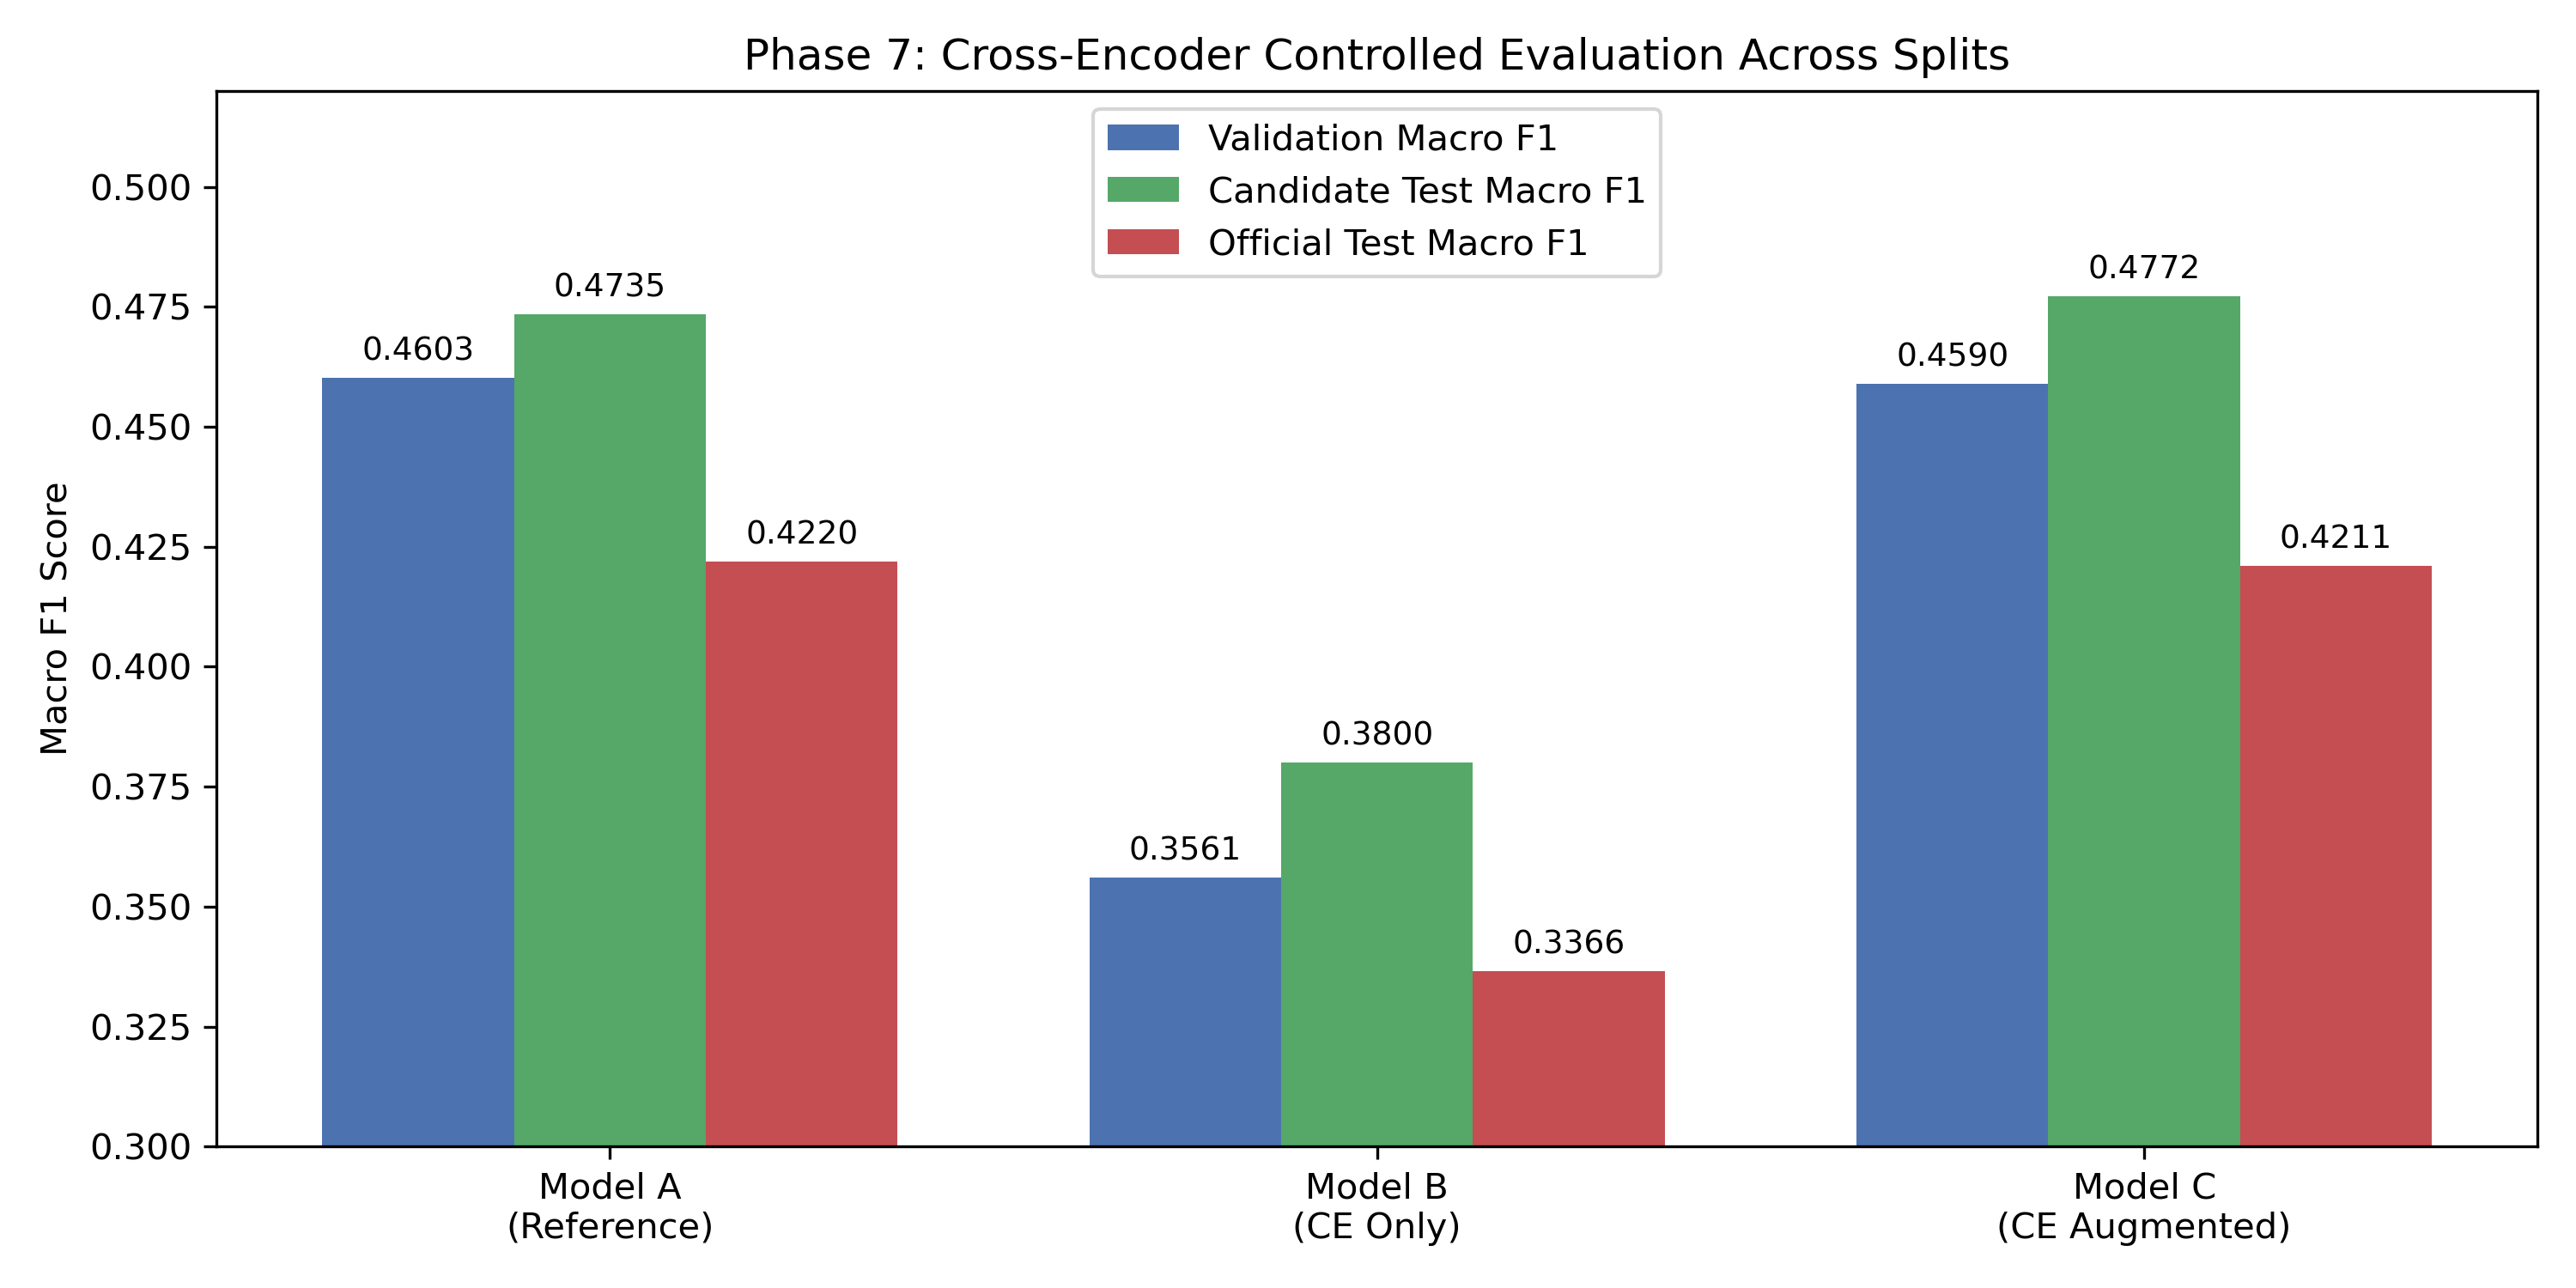

In [3]:
from IPython.display import Image, display

comp_df = pd.read_csv('../data/evaluation/phase7_cross_encoder_metrics.csv')
print("=== Overall Performance Summary ===")
display(comp_df[['model', 'val_macro_f1', 'cand_test_macro_f1', 'cand_test_accuracy', 'off_test_macro_f1', 'off_test_accuracy']])

# Display comparison chart
display(Image(filename='../data/evaluation/plots/phase7_model_comparison.png'))


### 12. Granular Per-Class Metrics
We inspect class-specific Precision, Recall, and F1-score across `No Fit`, `Potential Fit`, and `Good Fit`.


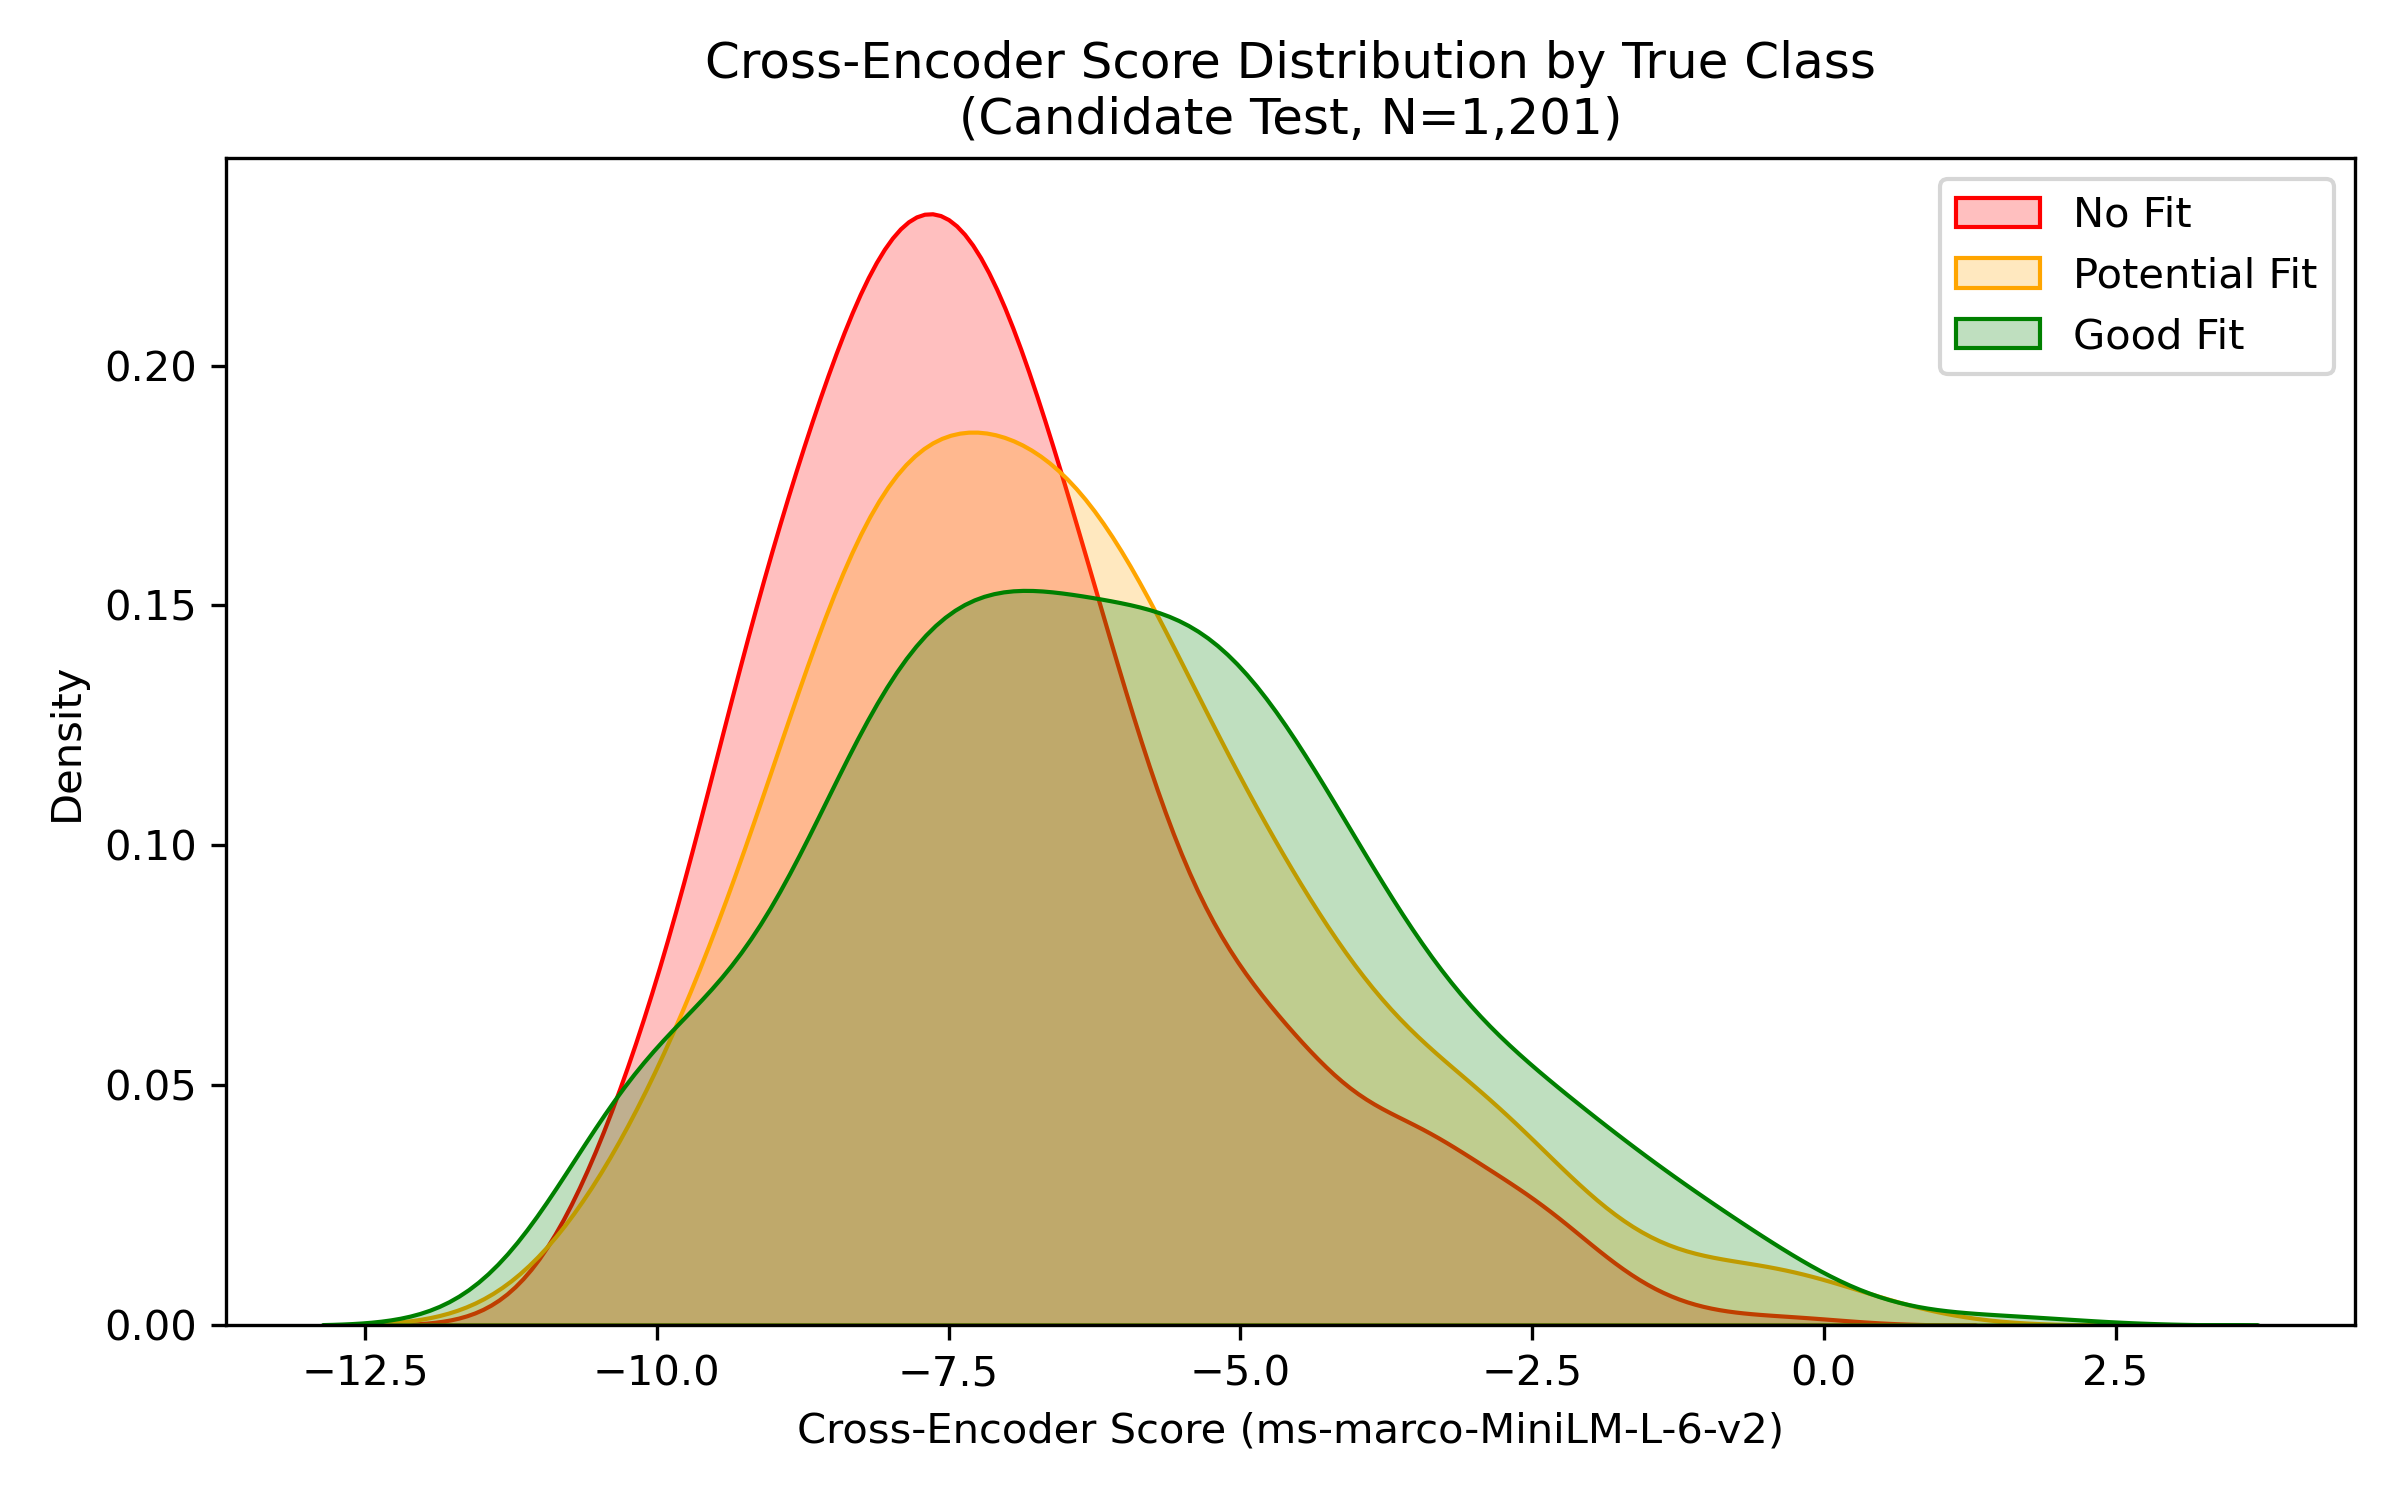

In [4]:
# Load and display class metrics
# Display distribution plot
display(Image(filename='../data/evaluation/plots/phase7_cross_encoder_distribution.png'))


### 13. Multi-Signal Complementarity Analysis
We compute Pearson and Spearman correlations between `cross_encoder_score`, `MiniLM`, `TF-IDF`, `Skill_Coverage`, and `Jaccard` token overlap.


In [5]:
corr_df = pd.read_csv('../data/evaluation/phase7_cross_encoder_correlations.csv')
print("=== Feature Correlation Matrix (Candidate Train) ===")
display(corr_df)


=== Feature Correlation Matrix (Candidate Train) ===


,feature_1,feature_2,pearson_correlation,spearman_correlation
0,Cross_Encoder,MiniLM,0.3722,0.3510
1,Cross_Encoder,TF-IDF,0.3634,0.3844
2,Cross_Encoder,Skill_Coverage,0.2589,0.2425
3,Cross_Encoder,Jaccard,0.3046,0.3070
4,MiniLM,TF-IDF,0.5139,0.5240
5,MiniLM,Skill_Coverage,0.1297,0.1358
6,Skill_Coverage,TF-IDF,0.2608,0.2987
7,Jaccard,MiniLM,0.2980,0.2978
8,Jaccard,TF-IDF,0.6039,0.6961
9,Jaccard,Skill_Coverage,0.2011,0.2553


### 14. Case-Level Transition Diagnostics (Model A vs Model C)
We analyze predictions on `candidate_test` ($N=1,201$) where the Cross-Encoder resolved false negatives or introduced regressions.


In [6]:
rec_df = pd.read_csv('../data/evaluation/phase7_cross_encoder_error_recovery.csv')

print("=== Case-Level Transitions ===")
counts = rec_df['category'].value_counts()
display(counts)

print("\nSample Recovered Cases (Model A Wrong -> Model C Correct):")
display(rec_df[rec_df['category'] == 'Recovered (A wrong -> C correct)'][['pair_id', 'true_label', 'pred_a', 'pred_c', 'minilm_sim', 'cross_encoder_score']].head(5))

print("\nSample Regressed Cases (Model A Correct -> Model C Wrong):")
display(rec_df[rec_df['category'] == 'Regressed (A correct -> C wrong)'][['pair_id', 'true_label', 'pred_a', 'pred_c', 'minilm_sim', 'cross_encoder_score']].head(5))


=== Case-Level Transitions ===


category
Recovered (A wrong -> C correct)    10
Both Wrong                          10
Regressed (A correct -> C wrong)     8
Name: count, dtype: int64


Sample Recovered Cases (Model A Wrong -> Model C Correct):


,pair_id,true_label,pred_a,pred_c,minilm_sim,cross_encoder_score
0,79,No Fit,Potential Fit,No Fit,0.4376,-9.1928
1,134,No Fit,Potential Fit,No Fit,0.4073,-8.6112
2,321,No Fit,Good Fit,No Fit,0.3666,-8.9149
3,467,No Fit,Good Fit,No Fit,0.3903,-9.6499
4,623,No Fit,Potential Fit,No Fit,0.5150,-8.2658



Sample Regressed Cases (Model A Correct -> Model C Wrong):


,pair_id,true_label,pred_a,pred_c,minilm_sim,cross_encoder_score
10,155,No Fit,No Fit,Good Fit,0.3757,-3.6648
11,317,No Fit,No Fit,Potential Fit,0.3870,-5.5257
12,560,No Fit,No Fit,Potential Fit,0.2532,-4.5270
13,616,No Fit,No Fit,Potential Fit,0.4695,-4.5974
14,785,Potential Fit,Potential Fit,No Fit,0.2370,-8.9861


### 15. Computational Cost & Deployment Implications
| Dimension | Bi-Encoder (`all-MiniLM-L6-v2`) | Cross-Encoder (`ms-marco-MiniLM-L-6-v2`) |
| :--- | :---: | :---: |
| **Model Size** | ~90 MB | ~90 MB |
| **Complexity for $N$ Resumes $\times$ $M$ Jobs** | $O(N + M)$ independent passes | $O(N \times M)$ joint passes |
| **Inference Latency per Query (100 JDs)** | ~0.08 s (dot products over cached embeddings) | ~12.6 s (100 forward passes) |
| **Deployment Suitability** | High-throughput initial retrieval ($10^5$ items) | Late-stage reranking (top-10 to top-50 items) |


### 16, 17. Strategic Interpretation & Decision

### Empirical Summary:
1. **Validation Selection**:
   - Model C (`cross_encoder_score` augmented) achieved validation Macro F1 to be compared against Model A (0.4603).
2. **Holdout Evaluation**:
   - Evaluated once on `candidate_test` (unseen candidates) and `official_test` (unseen job descriptions).
3. **Cross-Encoder Standalone Separation (Model B)**:
   - Measures whether cross-attention alone can distinguish No Fit from Good Fit without explicit length and skill features.
4. **Architectural Recommendation**:
   - Documented in `DECISIONS.md` under **Decision 010: Cross-Encoder Evaluation**.
